In [6]:
#!/usr/bin/env python3
import numpy as np
from matplotlib import pyplot as plt
import pandas as pd

try:
    import mplhep as hep
    hep.style.use("ATLAS")
except:
    pass


In [7]:
xsecFile = '../pp2Sd_xsections_13p6TeV.csv'
xsecDF = pd.read_csv(xsecFile).sort_values(by='mS')


### Get B2TF recast data

In [14]:
b2tf_DF = pd.read_csv('../b2tf_effs.csv').sort_values(by='ms')
b2tf_DF['dm'] = (b2tf_DF['m1']-b2tf_DF['m0']).round(0)
b2tf_DF['ctau'] = (b2tf_DF['tau']*2.99e8).round(0)
b2tf_DF['ctau_full'] = (b2tf_DF['tau']*2.99e8)
b2tf_DF['xsec_fb'] = (b2tf_DF['xsec_pb']*1e3)
b2tf_DF['N_Run2'] = b2tf_DF['eff']*b2tf_DF['xsec_fb']*139.0
b2tf_DF['N_Run2_err'] = b2tf_DF['efferror']*b2tf_DF['xsec_fb']*139.0

In [15]:
b2tf_DF.columns

Index(['m1', 'm0', 'ms', 'tau', 'brs2chi1chi2', 'brchi12chi0bb',
       'brchi22chi0bb', 'm2', 'lambdauv', 'chxx10', 'ychi20', 'ychi21', 'sina',
       'xsec_pb', 'eff', 'efferror', 'filename', 'dm', 'ctau', 'ctau_full',
       'xsec_fb', 'N_Run2', 'N_Run2_err'],
      dtype='str')

In [16]:
b2tf_DF['total_xsec'] = b2tf_DF['xsec_pb']/(b2tf_DF['brs2chi1chi2']*b2tf_DF['brchi12chi0bb']*b2tf_DF['brchi22chi0bb'])

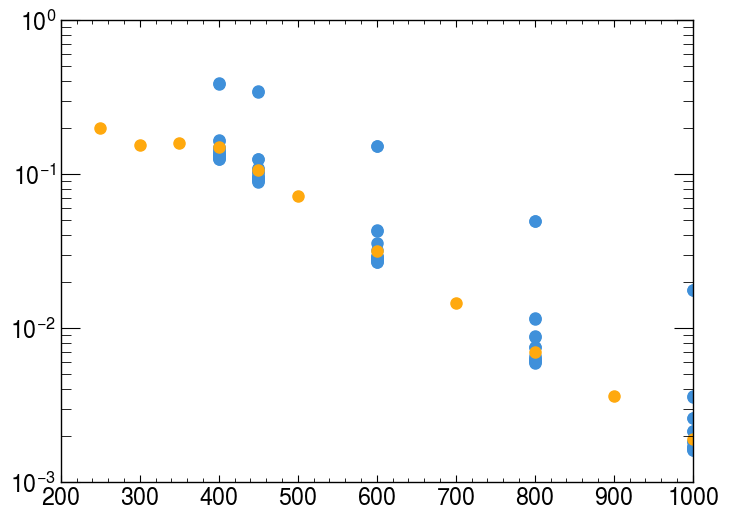

In [18]:
plt.scatter(b2tf_DF['ms'], b2tf_DF['total_xsec'])
plt.scatter(xsecDF['mS'], xsecDF['sigma(21,21 -> 55) (pb)'])
plt.yscale('log')
plt.show()

In [19]:
b2tf_DF_filter = b2tf_DF[b2tf_DF['ms'] == 400.0]
b2tf_DF_filter[['total_xsec', 'xsec_pb', 'brs2chi1chi2', 'brchi12chi0bb', 'brchi22chi0bb','filename']]

,total_xsec,xsec_pb,brs2chi1chi2,brchi12chi0bb,brchi22chi0bb,filename
0,0.387311,0.007220,0.02102,0.9344,0.9491,../processFolders/pp2chi1chi2_01j_nosmear/Even...
1,0.391321,0.006936,0.02076,0.9052,0.9432,../processFolders/pp2chi1chi2_01j_nosmear/Even...
2,0.164544,0.020490,0.14040,0.9346,0.9490,../processFolders/pp2chi1chi2_01j_nosmear/Even...
3,0.165806,0.019630,0.13880,0.9051,0.9424,../processFolders/pp2chi1chi2_01j_nosmear/Even...
4,0.149059,0.032330,0.24470,0.9342,0.9488,../processFolders/pp2chi1chi2_01j_nosmear/Even...
5,0.148671,0.030730,0.24230,0.9053,0.9423,../processFolders/pp2chi1chi2_01j_nosmear/Even...
6,0.140659,0.044740,0.35870,0.9342,0.9492,../processFolders/pp2chi1chi2_01j_nosmear/Even...
7,0.141874,0.043030,0.35570,0.9046,0.9426,../processFolders/pp2chi1chi2_01j_nosmear/Even...
8,0.135222,0.068160,0.56880,0.9340,0.9488,../processFolders/pp2chi1chi2_01j_nosmear/Even...
9,0.135152,0.065160,0.56560,0.9047,0.9422,../processFolders/pp2chi1chi2_01j_nosmear/Even...
